# Veritas SMS Guard: an explainable spam and scam filter for text messages

**What it does.** You give it a text message. It answers **legitimate**, **spam** or **likely scam**, gives a 0-100 risk score, and shows *which words and which parts of the link* triggered the verdict, so a person can decide before tapping.

**How it works (one paragraph).** A machine-learning layer (TF-IDF + logistic regression) learns what unwanted messages look like from 5,000+ labeled texts. Two rule layers add what that dataset cannot teach: a **link analyzer** (look-alike domains such as `usps-redelivery-help.xyz`, shorteners, raw IP addresses, login-style paths) and a **social-engineering detector** (urgency, fake prizes, fake authority, threats, requests for codes or payment). The layers are combined and every verdict lists its evidence.

**How to read this notebook.** Sections 1-3 are the data and the code. Sections 4-7 are the tests: a baseline comparison, a leakage check, our own modern messages, and an attack test. Section 8 summarizes. Run all cells top to bottom (about 3-4 minutes). On Google Colab the dataset downloads automatically.

> **Honesty note.** The public dataset only labels messages *ham* or *spam* and is from the mid-2000s. The "scam" tier is therefore derived by our link and tactic rules, not learned from scam labels. We test that tier separately on messages we wrote ourselves (Section 6) and report where it fails.

## 1. Data

We use the **SMS Spam Collection** (Almeida & Hidalgo, 2011; UCI Machine Learning Repository, CC BY 4.0): 5,574 English text messages labeled `ham` (legitimate) or `spam`. The cell below downloads it (or uses a local copy).

In [1]:
import io
import json
import os
import re
import urllib.request
import warnings
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

DATA_FILE = "SMSSpamCollection"
UCI_ZIP = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"


def get_dataset():
    if os.path.exists(DATA_FILE):
        return DATA_FILE
    try:
        raw_zip = urllib.request.urlopen(UCI_ZIP, timeout=30).read()
        with zipfile.ZipFile(io.BytesIO(raw_zip)) as z:
            z.extract(DATA_FILE)
        return DATA_FILE
    except Exception as err:
        print("Automatic download failed:", err)
    try:
        from google.colab import files  # only exists on Colab
        print("Please upload the file named SMSSpamCollection (from the UCI zip).")
        files.upload()
        return DATA_FILE
    except ImportError:
        raise FileNotFoundError("Put the file SMSSpamCollection next to this notebook. Download: " + UCI_ZIP)


DATA_PATH = get_dataset()

with open(DATA_PATH, encoding="utf-8", errors="replace") as f:
    pairs = [line.rstrip("\n").split("\t", 1) for line in f if "\t" in line]
raw = pd.DataFrame(pairs, columns=["label", "text"])

RESULTS = {}   # filled in as we go, saved to results.json at the end
RESULTS["dataset_raw"] = {"messages": int(len(raw)), "ham": int((raw.label == "ham").sum()),
                          "spam": int((raw.label == "spam").sum()),
                          "exact_duplicate_rows": int(raw.text.duplicated().sum())}
print(raw.groupby("label").size().to_string())
print(f"\nTotal: {len(raw)} messages. Spam share: {(raw.label == 'spam').mean():.1%}")
print(f"Exact duplicate texts: {raw.text.duplicated().sum()}  (we remove these before splitting)\n")
print(raw.sample(6, random_state=1).to_string(max_colwidth=90))

label
ham     4827
spam     747

Total: 5574 messages. Spam share: 13.4%
Exact duplicate texts: 403  (we remove these before splitting)

     label                                                                                       text
1447   ham  Looks like u wil b getting a headstart im leaving here bout 2.30ish but if u r despera...
2032   ham                             I noe la... U wana pei bf oso rite... K lor, other days den...
4432   ham                                             2mro i am not coming to gym machan. Goodnight.
4888  spam  Todays Vodafone numbers ending with 4882 are selected to a receive a £350 award. If yo...
5276   ham  Hi. Hope ur day * good! Back from walk, table booked for half eight. Let me know when ...
5463   ham                                        Ok i thk i got it. Then u wan me 2 come now or wat?


## 2. The system

The code below is the whole system. It is identical to `veritas_sms_guard.py` in the repository (this notebook is generated from that file), so what you test here is exactly what the web demo runs.

It has four parts: **2a** cleaning, **2b** the ML layer, **2c** the link analyzer, **2d** the social-engineering detector, and **2e** the decision logic.

In [2]:
"""
Veritas SMS Guard
=================
Classifies a text message as  LEGITIMATE | SPAM | SCAM  and explains why.

Architecture (hybrid, so every verdict is explainable):

  1. ML layer     TF-IDF (word + char n-grams) + style features -> Logistic Regression.
                  Trained on SMSSpamCollection (ham vs spam). Gives P(unwanted).
  2. Link layer   Parses every URL and checks for hallmarks of malicious links
                  (shorteners, raw-IP hosts, punycode, '@' tricks, brand look-alikes,
                  risky TLDs, login-style paths, .apk downloads ...).
  3. Tactic layer Detects social-engineering tactics (urgency, fake prize, authority
                  impersonation, fear/threat, credential requests, payment requests,
                  delivery lures, premium-rate callbacks, family impersonation ...).
  4. Decision     unwanted = ML says so  OR  rules independently find strong evidence.
                  Unwanted + deception signals -> SCAM, otherwise -> SPAM.

The dataset only labels ham/spam. The SCAM tier is therefore *derived* by the link and
tactic layers (weak supervision), not learned from ground-truth scam labels.

Usage
-----
  python veritas_sms_guard.py train   --data SMSSpamCollection --out veritas_model.joblib
  python veritas_sms_guard.py predict "message text" [--json]
  python veritas_sms_guard.py demo
"""
from __future__ import annotations

import argparse
import html
import json
import re
import sys
import unicodedata
from dataclasses import dataclass, field
from pathlib import Path
from typing import Optional
from urllib.parse import urlparse

import joblib
import numpy as np
from scipy.sparse import csr_matrix
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import FeatureUnion, Pipeline

DEFAULT_MODEL = Path("veritas_model.joblib")

# --------------------------------------------------------------------------- #
# Decision thresholds (rule layer). The ML threshold is learned during training.
# --------------------------------------------------------------------------- #
RULE_ALERT = 50     # rule-only evidence strong enough to flag, even if ML says ham
SCAM_SCORE = 35     # link_risk + deception needed to call an unwanted msg a SCAM

### 2a. Cleaning

Two details matter. First, the dataset contains anonymization placeholders (`<#>`, `<DECIMAL>`) that appear almost only in legitimate messages, which would let a model "cheat". We strip them. Second, `harden()` undoes two tricks scammers use to dodge filters: invisible characters and look-alike letters (for example a Cyrillic "a" inside "paypal"). Section 7 tests this.

In [3]:
_ARTIFACTS = re.compile(r"<\s*(?:#|decimal|time|url|email)\s*>", re.I)

# Anti-evasion ("hardening"). Scammers dodge filters with invisible characters and
# look-alike letters (a Cyrillic 'a' in "paypal"). We undo the two easiest tricks.
# Set HARDEN_ENABLED = False to switch it off (used for the before/after experiment).
HARDEN_ENABLED = True
_ZERO_WIDTH = dict.fromkeys(map(ord, "​‌‍⁠﻿­"), None)
_HOMOGLYPHS = {
    # Cyrillic lower / upper case
    "а": "a", "е": "e", "о": "o", "р": "p", "с": "c", "х": "x",
    "у": "y", "і": "i", "ј": "j", "ѕ": "s", "ԁ": "d",
    "А": "A", "В": "B", "Е": "E", "К": "K", "М": "M", "Н": "H",
    "О": "O", "Р": "P", "С": "C", "Т": "T", "Х": "X",
    # Greek
    "ο": "o", "ν": "v", "Α": "A", "Β": "B", "Ε": "E", "Η": "H",
    "Ι": "I", "Κ": "K", "Μ": "M", "Ν": "N", "Ο": "O", "Ρ": "P",
    "Τ": "T", "Χ": "X",
}
_HOMOGLYPH_TABLE = str.maketrans(_HOMOGLYPHS)


def harden(text: str) -> str:
    """Normalise compatibility characters, drop zero-width characters, map look-alikes to Latin."""
    t = unicodedata.normalize("NFKC", text)
    return t.translate(_ZERO_WIDTH).translate(_HOMOGLYPH_TABLE)


def clean_text(text: str) -> str:
    """Unescape HTML, undo simple obfuscation, and strip the anonymisation placeholders
    (<#>, <DECIMAL> ...) that appear almost only in ham in SMSSpamCollection (a data leak)."""
    t = html.unescape(text)
    if HARDEN_ENABLED:
        t = harden(t)
    t = _ARTIFACTS.sub(" ", t)
    # re-join obfuscated hosts such as "http://wap. xxxclub.com"
    t = re.sub(r"(?i)((?:https?://|www\.)\S*?\.)\s+(?=\w)", r"\1", t)
    return re.sub(r"\s+", " ", t).strip()


_TLDS = (r"com|net|org|co\.uk|uk|biz|info|tv|xyz|top|click|link|tk|ml|ga|cf|gq|ru|cn|ly|gl|"
         r"ws|site|online|live|club|shop|icu|buzz|work|loan|vip|app|ac|pw|su|cyou|rest|zip|mov")
URL_RE = re.compile(
    r"""(?ix)
    (?<![@\w.])
    (?:
        (?:https?://|ftp://)[^\s<>"'()]+
      | www\.[^\s<>"'()]+
      | (?:[a-z0-9](?:[a-z0-9\-]{0,61}[a-z0-9])?\.)+(?:""" + _TLDS + r""")(?![a-z0-9@\-])(?:[/?#][^\s<>"'()]*)?
    )"""
)


def find_urls(text: str) -> list[str]:
    return [m.group(0).rstrip(".,;:!?)'\"") for m in URL_RE.finditer(text)]


def normalize_for_ml(text: str) -> str:
    t = clean_text(text).lower()
    # Links are removed on purpose: in SMSSpamCollection only 9 of ~4.5k ham messages contain a URL
    # (vs 114 spam), so the model would learn "has a link => spam". Links are judged by the link layer.
    t = URL_RE.sub(" ", t)
    t = re.sub(r"[£$€]\s?\d[\d,\.]*", " moneyamt ", t)
    t = re.sub(r"\d{5,}", " longnum ", t)
    return re.sub(r"\s+", " ", t).strip()

### 2b. The ML layer

Word and character n-gram TF-IDF features plus a few style features (length, capital letters, digits, currency symbols), fed to logistic regression with balanced class weights. We deliberately **remove URLs from the text the model sees**: in this dataset only 9 legitimate messages contain a link, versus 114 spam messages, so a model would learn "any link means spam" and wrongly flag real shipping notices. Links are judged by the link analyzer instead.

In [4]:
class StyleFeatures(BaseEstimator, TransformerMixin):
    """Small, bounded [0,1] stylistic features that survive tokenisation."""

    names = ["length", "digit_ratio", "upper_ratio", "exclaim", "currency",
             "long_number", "shortcode_cta", "caps_words"]

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        rows = []
        for raw in X:
            t = clean_text(raw)
            n = max(len(t), 1)
            letters = [c for c in t if c.isalpha()]
            words = t.split()
            rows.append([
                min(len(t) / 200.0, 1.0),
                sum(c.isdigit() for c in t) / n,
                (sum(c.isupper() for c in letters) / len(letters)) if letters else 0.0,
                min(t.count("!") / 3.0, 1.0),
                1.0 if re.search(r"[£$€]\s?\d", t) else 0.0,
                1.0 if re.search(r"\d{8,}", t) else 0.0,
                1.0 if SHORTCODE_RE.search(t) else 0.0,
                min(sum(1 for w in words if len(w) > 2 and w.isupper()) / 5.0, 1.0),
            ])
        return csr_matrix(np.array(rows, dtype=np.float64))


def build_pipeline(C: float = 10.0) -> Pipeline:
    feats = FeatureUnion([
        ("word", TfidfVectorizer(preprocessor=normalize_for_ml, lowercase=False,
                                 ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("char", TfidfVectorizer(preprocessor=normalize_for_ml, lowercase=False,
                                 analyzer="char_wb", ngram_range=(2, 5), min_df=3,
                                 sublinear_tf=True)),
        ("style", StyleFeatures()),
    ])
    clf = LogisticRegression(C=C, class_weight="balanced", max_iter=3000, solver="liblinear")
    return Pipeline([("features", feats), ("clf", clf)])

### 2c. The link analyzer

Each URL is parsed (never opened) and checked for: shorteners, raw IP hosts, punycode, the `@` trick, risky domain endings, brand look-alikes (a domain that mentions `usps` or `paypal` but is not theirs), long hyphen-stuffed names, login-style paths, program downloads and odd ports. Every finding carries a plain-English reason.

In [5]:
SHORTENERS = {"bit.ly", "tinyurl.com", "t.co", "goo.gl", "ow.ly", "is.gd", "cutt.ly", "rb.gy",
              "shorturl.at", "tiny.cc", "buff.ly", "rebrand.ly", "bl.ink", "t.ly", "lnkd.in",
              "s.id", "v.gd", "x.co", "soo.gd", "qr.net"}
SUSPICIOUS_TLDS = {"xyz", "top", "click", "link", "tk", "ml", "ga", "cf", "gq", "icu", "buzz",
                   "loan", "work", "vip", "site", "online", "cyou", "rest", "zip", "mov", "pw",
                   "su", "ru", "cn"}
WEAK_TLDS = {"biz", "info"}
TWO_PART_TLDS = {"co.uk", "org.uk", "ac.uk", "gov.uk", "com.au", "co.in", "co.za", "com.br"}

BRANDS: dict[str, set[str]] = {
    "paypal": {"paypal.com"}, "amazon": {"amazon.com", "amazon.co.uk", "amazon.de", "amazon.in",
                                          "amazon.ca"},
    "apple": {"apple.com", "icloud.com"}, "icloud": {"icloud.com"}, "netflix": {"netflix.com"},
    "usps": {"usps.com"}, "fedex": {"fedex.com"}, "dhl": {"dhl.com", "dhl.de"}, "ups": {"ups.com"},
    "chase": {"chase.com"}, "wellsfargo": {"wellsfargo.com"}, "bankofamerica": {"bankofamerica.com"},
    "citibank": {"citi.com", "citibank.com"}, "microsoft": {"microsoft.com", "live.com", "office.com"},
    "google": {"google.com"}, "irs": {"irs.gov"}, "royalmail": {"royalmail.com"},
    "venmo": {"venmo.com"}, "coinbase": {"coinbase.com"}, "facebook": {"facebook.com", "fb.com"},
    "instagram": {"instagram.com"}, "whatsapp": {"whatsapp.com"}, "vodafone": {"vodafone.co.uk", "vodafone.com"},
    "barclays": {"barclays.co.uk", "barclays.com"}, "hsbc": {"hsbc.com", "hsbc.co.uk"},
    "lloyds": {"lloydsbank.com"}, "santander": {"santander.co.uk", "santander.com"},
    "zelle": {"zelle.com", "zellepay.com"}, "cashapp": {"cash.app"}, "evri": {"evri.com"},
}
_SHORT_BRANDS = {"ups", "dhl", "irs", "usps"}   # must match a whole host token
_LEET = str.maketrans({"0": "o", "1": "l", "3": "e", "5": "s", "$": "s"})


@dataclass
class Signal:
    id: str
    kind: str            # "link" | "tactic" | "promo"
    weight: int
    label: str
    why: str
    evidence: str = ""
    critical: bool = False


def _split_host(host: str):
    labels = host.split(".")
    base = 3 if len(labels) >= 3 and ".".join(labels[-2:]) in TWO_PART_TLDS else 2
    return ".".join(labels[-base:]), labels[:-base], labels[-1]


def analyze_url(url: str) -> list[Signal]:
    sigs: list[Signal] = []
    has_scheme = bool(re.match(r"(?i)^[a-z]+://", url))
    try:
        pr = urlparse(url if has_scheme else "http://" + url)
        host = (pr.hostname or "").lower()
        port = pr.port
    except ValueError:
        return [Signal("malformed_url", "link", 15, "Malformed link", "The link cannot be parsed "
                       "cleanly, which is common in obfuscated phishing URLs.", url)]
    if not host:
        return sigs

    def add(id_, w, label, why, critical=False):
        sigs.append(Signal(id_, "link", w, label, why, url[:70], critical))

    if re.fullmatch(r"\d{1,3}(?:\.\d{1,3}){3}", host):
        add("ip_host", 35, "Link points to a raw IP address",
            "Legitimate companies use domain names. Raw IPs are typical of throw-away phishing servers.", True)
    if "xn--" in host:
        add("punycode", 35, "Link uses punycode (look-alike characters)",
            "Punycode can disguise a domain with foreign characters that look like Latin letters.", True)
    if pr.username is not None or "@" in url.split("//", 1)[-1].split("/", 1)[0]:
        add("userinfo_trick", 35, "Link contains an '@' trick",
            "Everything before the '@' is ignored by the browser, so the real destination is hidden.", True)
    if host in SHORTENERS:
        add("shortener", 25, "Shortened link",
            "Link shorteners hide the real destination, so you can't judge it before tapping.")
    registered, subs, tld = _split_host(host)
    if tld in SUSPICIOUS_TLDS:
        add("risky_tld", 20, f"Risky domain ending (.{tld})",
            "These cheap or free domain endings are heavily abused for phishing and scams.")
    elif tld in WEAK_TLDS:
        add("weak_tld", 8, f"Low-trust domain ending (.{tld})",
            "Commonly used by bulk-marketing and scam sites.")
    # brand look-alike: brand name used in the host but the registered domain isn't the brand's
    h = host.translate(_LEET)
    tokens = [t for t in re.split(r"[.\-_]", h) if t]
    for brand, official in BRANDS.items():
        hit = (brand in tokens) if brand in _SHORT_BRANDS else any(
            t == brand or t.startswith(brand) or t.endswith(brand) for t in tokens)
        if hit and not any(host == d or host.endswith("." + d) for d in official):
            add("brand_lookalike", 45, f"Link impersonates '{brand}'",
                f"The domain mentions {brand} but is not owned by {brand}. This is the core "
                "trick of phishing links.", True)
            break
    if host.count("-") >= 3 or max((len(l) for l in host.split(".")), default=0) > 28:
        add("stuffed_domain", 10, "Long, hyphen-stuffed domain",
            "Scam domains often chain keywords like 'secure-login-verify-account'.")
    n_sub = len([s for s in subs if s != "www"])
    if n_sub >= 3:
        add("deep_subdomain", 10, "Unusually deep subdomain chain",
            "Many subdomains are used to push the real domain out of view on small screens.")
    path = (pr.path + "?" + (pr.query or "")).lower()
    if re.search(r"(?:login|signin|sign-in|verify|secure|update|account|confirm|wallet|billing|unlock)", path):
        add("credential_path", 10, "Link path suggests a login / verification page",
            "Pages named 'login', 'verify' or 'update' are where stolen credentials are collected.")
    if path.split("?")[0].endswith((".apk", ".exe", ".scr", ".msi", ".dmg")):
        add("file_download", 30, "Link downloads an app or program file",
            "Direct .apk/.exe downloads are a common route for mobile malware.", True)
    if port not in (None, 80, 443):
        add("odd_port", 10, "Link uses a non-standard port", "Unusual for legitimate consumer websites.")
    if has_scheme and url.lower().startswith("http://"):
        add("no_https", 5, "Link is not encrypted (http)", "Legitimate account pages use https.")
    return sigs

### 2d. The social-engineering detector

About 20 tactics, each a small set of patterns with a weight and a plain-English explanation: unexpected prizes, urgency, impersonating a bank or carrier, fake delivery problems, threats, requests to "verify" an account, requests for passwords or codes, unusual payment methods (gift cards, crypto), "Hi Mum, new number" family impersonation, premium-rate callbacks and more. Patterns skip negated uses ("never share your password").

In [6]:
SHORTCODE_RE = re.compile(r"(?i)\b(?:txt|text|reply|send|sms)\b[^.\n]{0,40}?\bto\s*(?:no\s*[:.]?\s*)?\d{4,6}\b")
_NEG = re.compile(r"(?i)(?:never|do not|don'?t|dont|won'?t|will not|not)\b[^.!?]{0,40}$")


@dataclass
class Tactic:
    id: str
    kind: str
    weight: int
    label: str
    why: str
    patterns: list[str]
    critical: bool = False
    skip_if_negated: bool = False
    _rx: list = field(default_factory=list, repr=False)

    def __post_init__(self):
        self._rx = [re.compile(p, re.I | re.S) for p in self.patterns]

    def match(self, text: str) -> Optional[Signal]:
        for rx in self._rx:
            for m in rx.finditer(text):
                if self.skip_if_negated and _NEG.search(text[max(0, m.start() - 45):m.start()]):
                    continue
                return Signal(self.id, self.kind, self.weight, self.label, self.why,
                              m.group(0).strip()[:60], self.critical)
        return None


_CRED_OBJ = (r"(?:password|pass ?code|pin|otp|one[- ]time (?:code|pass ?code)|verification code|security code|"
             r"cvv|ssn|social security|card (?:number|details)|account (?:number|details|no)|bank details|"
             r"log ?in details|credentials|date of birth|dob|mother'?s maiden)")

TACTICS: list[Tactic] = [
    Tactic("false_win", "tactic", 25, "Unexpected prize / win notice",
           "You can't win a draw you never entered. Fake prizes drive advance-fee fraud and premium-rate traps.",
           [r"\byou(?:'ve|\s+have|\s+are|\s*r)?\s+(?:just\s+)?(?:been\s+)?(?:won|selected|chosen|awarded)(?!'?t)\b",
            r"\b(?:u|you)\s+(?:have\s+|ave\s+)?won(?!'?t)\b", r"\bwinner\b", r"\b(?:has|have)\s+won(?!'?t)\b",
            r"\b(?:ur|your)\s+(?:mobile\s+)?(?:no\.?|number)\b.{0,40}\b(?:won|awarded|selected)\b",
            r"\bguaranteed\b.{0,20}(?:cash|prize|award|£|\$)", r"\bawarded\b", r"\b(?:is|are)\s+yours\b",
            r"\b(?:bonus|caller)\s+prize\b", r"\bunredeemed\b"]),
    Tactic("reward_hype", "tactic", 10, "Prize / reward language",
           "Offers of cash, vouchers or free gifts are bait to get you to click, call or pay.",
           [r"\b(?:congratulations|congrats)\b", r"\b(?:prizes?|jackpot|vouchers?|reward|cash prize)\b",
            r"\bfree (?:gift|entry|holiday|phone|camera|msg|message|ringtone|tone|mobile|membership)\b",
            r"[£$€]\s?\d[\d,]*"]),
    Tactic("urgency", "tactic", 10, "Urgency / pressure",
           "Scammers rush you so you act before thinking or verifying.",
           [r"\burgent(?:ly)?\b", r"\bimmediately\b", r"\basap\b", r"\bright away\b", r"\bact now\b",
            r"\bfinal (?:notice|attempt|chance|reminder|warning)\b", r"\blast chance\b",
            r"\b(?:2nd|3rd|second|third) (?:attempt|notice)\b", r"\bvalid\s*(?:for\s*)?\d+\s*(?:hrs?|hours?)\b",
            r"\bwithin\s+\d+\s*(?:hrs?|hours?|days?|mins?|minutes?)\b", r"\bexpir(?:es?|ing)\b",
            r"\bhurry\b", r"\blimited time\b", r"\btoday only\b", r"\bbefore the lines close\b",
            r"\bcall\b(?:\s+\S+){0,4}?\s+(?:now|immediately)\b"]),
    Tactic("authority", "tactic", 20, "Claims to be a company or authority",
           "Impersonating a bank, carrier, tax agency or 'customer service' borrows trust you'd give the real one.",
           [r"\bvalued (?:network )?customer\b", r"\bnetwork (?:customer|operator)\b",
            r"\bcustomer (?:service|care|loyalty)s?\b", r"\baccount statement\b",
            r"\b(?:security|fraud)\s+(?:alert|team|department|dept)\b",
            r"\byour\s+(?:bank|account|card|debit card|credit card|parcel|package|delivery|order|payment|apple id|"
            r"paypal|netflix|amazon|subscription)\b",
            r"^\s*[\[(]?(?:usps|fedex|dhl|ups|royal mail|hmrc|irs|paypal|netflix|amazon|apple|chase|wells fargo|"
            r"bank of america|microsoft|evri|dpd)\b"]),
    Tactic("delivery_lure", "tactic", 20, "Fake delivery / parcel problem",
           "'Missed delivery' texts are the most common smishing lure today.",
           [r"\b(?:delivery|parcel|package|shipment)\b.{0,60}\b(?:waiting|failed|unable|re-?schedule|held|"
            r"undeliverable|could not|couldn'?t|customs|redeliver|incomplete address)\b"]),
    Tactic("fear_threat", "tactic", 20, "Fear / threat",
           "Threats of lockouts, fines or arrest are used to panic you into complying.",
           [r"\b(?:account|card|access)\b.{0,30}\b(?:suspend(?:ed)?|locked|blocked|deactivated|on hold|disabled)\b",
            r"\b(?:suspicious|unusual|unauthori[sz]ed)\s+(?:activity|login|sign-?in|transaction)\b",
            r"\bcompromised\b", r"\blegal action\b", r"\bwill be arrested\b", r"\barrest warrant\b",
            r"\bwarrant for (?:your )?arrest\b", r"\bbailiff\b", r"\bunpaid\s+(?:tax|taxes|toll|fine|balance|bill)",
            r"\bwill be (?:closed|terminated|cancelled|canceled|disconnected)\b"]),
    Tactic("verify_action", "tactic", 25, "Asks you to 'verify' or 'update' something",
           "Real companies rarely ask you to confirm account details through a text link.",
           [r"\b(?:verify|confirm|validate|unlock|reactivate|restore|update)\b.{0,30}\b"
            r"(?:account|identity|information|details|access|card|payment|address|now)\b"],
           skip_if_negated=True),
    Tactic("credential_request", "tactic", 30, "Asks for passwords, PINs or personal data",
           "Genuine banks and carriers never ask for passwords, PINs or one-time codes by text.",
           [r"\b(?:verify|confirm|update|validate|re-?enter|provide|send|share|reply with|give)\b.{0,40}?\b" + _CRED_OBJ + r"\b",
            r"\b(?:your|ur)\s+(?:name and address|address and dob|dob)\b"],
           critical=True, skip_if_negated=True),
    Tactic("payment_request", "tactic", 25, "Asks for unusual payment",
           "Gift cards, wire transfers, crypto and 'fees' are favoured because they can't be reversed.",
           [r"\b(?:gift ?cards?|itunes card|google play card|steam card|western union|moneygram|wire transfer|"
            r"bitcoin|crypto(?:currency)?|btc|cash ?app|zelle|processing fee|registration fee|release fee|"
            r"transfer fee)\b"], critical=True),
    Tactic("money_ask", "tactic", 15, "Asks you to send a specific amount of money",
           "Direct requests for a cash transfer from an unverified sender are a hallmark of impersonation scams.",
           [r"\b(?:send|transfer|lend|loan|wire)\s+(?:me\s+)?(?:about\s+)?[£$€]\s?\d"]),
    Tactic("family_impersonation", "tactic", 30, "'New number' family impersonation",
           "'Hi Mum, I lost my phone' is a well-known scam: criminals pose as a relative to ask for money.",
           [r"\b(?:mum|mom|dad|nan|grandma|grandpa)\b.{0,60}\b(?:new number|lost my phone|broke my phone|"
            r"phone (?:broke|is broken|died)|dropped my phone)\b",
            r"\b(?:new number|lost my phone|broke my phone)\b.{0,60}\b(?:mum|mom|dad)\b"], critical=True),
    Tactic("secrecy", "tactic", 10, "Asks for secrecy",
           "Isolating you from people who could spot the scam is a classic manipulation tactic.",
           [r"\bdon'?t tell (?:anyone|anybody)\b", r"\bkeep (?:this|it) (?:a )?(?:secret|between us|private|confidential)\b",
            r"\btell no ?one\b"]),
    Tactic("curiosity_bait", "tactic", 15, "Curiosity / secret-admirer bait",
           "'Someone fancies you' hooks make you call a premium-rate number to 'find out who'.",
           [r"\bsecret admirer\b", r"\bsomeone (?:u |you )?know\b.{0,40}\b(?:contact|fancies|asked)\b",
            r"\bfancies you\b", r"\bfind out who\b", r"\bdating service\b", r"\breveal who\b"]),
    Tactic("easy_money", "tactic", 30, "Too-good-to-be-true earnings / investment",
           "Guaranteed income, 'no experience' jobs and investment tips are staples of job and crypto scams.",
           [r"\bearn\s+[£$€]?\s?\d[\d,]*\s*(?:/|per|a)?\s*(?:day|daily|hour|hr|week|weekly)\b",
            r"\bno experience (?:needed|required|necessary)\b", r"\binvestment opportunity\b",
            r"\bguaranteed returns?\b", r"\bdouble your money\b"]),
    Tactic("offsite_move", "tactic", 15, "Pushes you onto another app",
           "Moving the chat to WhatsApp/Telegram takes it out of reach of carrier spam filters.",
           [r"\b(?:message|text|contact|add|dm)\s+(?:me\s+)?(?:on|via)\s+(?:whatsapp|telegram|signal)\b",
            r"\b(?:whatsapp|telegram)\b.{0,20}\b(?:to start|to apply|to join)\b"]),
    Tactic("premium_callback", "tactic", 20, "Asks you to call a premium-rate number",
           "UK 09xx / 0871-0873 numbers charge you heavily per minute; calling is how the scam makes money.",
           [r"(?<!\d)(?:\+?44\s?)?0?9[01]\d{8,9}", r"(?<!\d)0?87[0-3]\d{7,8}"]),
    Tactic("shortcode_cta", "tactic", 10, "Asks you to text a short code",
           "Texting a 5-digit short code often enrols you in a recurring paid subscription.",
           [SHORTCODE_RE.pattern]),
    Tactic("cost_notice", "promo", 10, "Per-message / per-minute charges",
           "Fine print about pence-per-message or per-minute rates signals a paid-service trap.",
           [r"\b\d{2,3}p(?:pm|/?(?:msg|min|wk|txt|text|per))?\b", r"\b(?:ppm|p/min|p per min|per min(?:ute)?)\b",
            r"[£$]\s?\d+(?:\.\d+)?\s?(?:/|per|a)\s?(?:wk|week|msg|min|day|month)\b", r"\bsubscri(?:be|bed|ption)\b",
            r"\b(?:charged|billed)\b"]),
    Tactic("optout_language", "promo", 5, "Opt-out / T&C boilerplate",
           "Bulk marketing texts carry STOP / T&C wording.",
           [r"\b(?:txt|text|reply)\s+stop\b", r"\bstop to (?:end|opt out|cancel|unsubscribe)\b", r"\bunsubscribe\b",
            r"\bopt[- ]?out\b", r"\bt&c'?s?\b", r"\btsandcs\b", r"\bterms (?:and|&) conditions\b"]),
    Tactic("marketing_offer", "promo", 5, "Bulk marketing content",
           "Ringtones, handset upgrades, adult chat and competitions are typical bulk-spam themes.",
           [r"\bringtones?\b", r"\bpoly(?:phonic)?\b", r"\bwallpaper\b", r"\blogo\b", r"\bsexy\b", r"\bhorny\b",
            r"\bsingles?\b", r"\bchat line\b", r"\bupgrade\b", r"\bcamcorder\b", r"\bline rental\b",
            r"\bdouble mins\b", r"\bnew (?:video )?(?:phone|mobile|handset)\b", r"\bweekly (?:comp|draw)\b",
            r"\bwkly comp\b", r"\bchance to win\b", r"\bquiz\b", r"\bdogging\b"]),
]

### 2e. Putting it together

A message is **flagged** if the ML layer says so *or* the rules independently find strong evidence. A flagged message with enough deception signals (or one critical signal such as a look-alike domain) is a **scam**; otherwise it is **spam**. The ML threshold is not hand-picked: it is chosen on training data to catch as much spam as possible while wrongly flagging at most 0.5% of legitimate messages.

In [7]:
@dataclass
class Analysis:
    signals: list[Signal]
    link_risk: int
    deception: int
    promo: int
    urls: list[str]

    @property
    def rule_risk(self) -> int:
        return min(100, self.link_risk + self.deception)

    @property
    def critical(self) -> bool:
        return any(s.critical for s in self.signals)


def analyze(text: str) -> Analysis:
    t = clean_text(text)
    urls = find_urls(t)
    link: dict[str, Signal] = {}
    for u in urls:
        for s in analyze_url(u):
            if s.id not in link or s.weight > link[s.id].weight:
                link[s.id] = s
    signals = list(link.values())
    for tac in TACTICS:
        s = tac.match(t)
        if s:
            signals.append(s)
    return Analysis(
        signals=sorted(signals, key=lambda s: -s.weight),
        link_risk=min(100, sum(s.weight for s in signals if s.kind == "link")),
        deception=sum(s.weight for s in signals if s.kind == "tactic"),
        promo=sum(s.weight for s in signals if s.kind == "promo"),
        urls=urls,
    )


def decide(p_unwanted: float, a: Analysis, ml_threshold: float):
    """Return (label, risk_score 0-100, flagged_by)."""
    by_ml = p_unwanted >= ml_threshold
    by_rules = a.rule_risk >= RULE_ALERT
    risk = 100 * (1 - (1 - p_unwanted) * (1 - a.rule_risk / 100))
    if not (by_ml or by_rules):
        return "legitimate", round(risk), "none"
    scam_score = a.link_risk + a.deception
    label = "scam" if (scam_score >= SCAM_SCORE or a.critical) else "spam"
    flagged_by = "ml+rules" if (by_ml and by_rules) else ("ml" if by_ml else "rules")
    return label, round(max(risk, 50 if by_rules else 50)), flagged_by


ADVICE = {
    "scam": "Do NOT tap links, call numbers or reply (even 'STOP'). If it claims to be a company, "
            "contact them through their official app or website instead. Report and delete.",
    "spam": "Unsolicited promotion. Safe to delete. Texting a short code or replying can enrol you "
            "in paid services.",
    "legitimate": "No strong red flags. Still verify any unexpected request through a channel you trust.",
}


@dataclass
class Verdict:
    label: str
    risk_score: int
    ml_probability: float
    flagged_by: str
    signals: list[Signal]
    urls: list[str]
    advice: str

    def to_dict(self):
        return {
            "label": self.label, "risk_score": self.risk_score,
            "ml_probability_unwanted": round(self.ml_probability, 4), "flagged_by": self.flagged_by,
            "urls": self.urls,
            "signals": [{"id": s.id, "type": s.kind, "weight": s.weight, "finding": s.label,
                         "why_it_matters": s.why, "evidence": s.evidence} for s in self.signals],
            "advice": self.advice,
        }

    def pretty(self) -> str:
        icon = {"scam": "🚨", "spam": "⚠️ ", "legitimate": "✅"}[self.label]
        out = [f"{icon} {self.label.upper()}   (risk {self.risk_score}/100, "
               f"ML P(unwanted)={self.ml_probability:.2f}, flagged by: {self.flagged_by})"]
        links = [s for s in self.signals if s.kind == "link"]
        tactics = [s for s in self.signals if s.kind == "tactic"]
        promo = [s for s in self.signals if s.kind == "promo"]
        for title, group in (("Link red flags", links), ("Social-engineering tactics", tactics),
                             ("Marketing markers", promo)):
            if group:
                out.append(f"  {title}:")
                out += [f"    - {s.label}  [{s.evidence}]" for s in group]
        out.append(f"  Advice: {self.advice}")
        return "\n".join(out)


class SmsGuard:
    def __init__(self, pipeline: Pipeline, ml_threshold: float):
        self.pipeline = pipeline
        self.ml_threshold = ml_threshold

    def predict_proba(self, texts) -> np.ndarray:
        return self.pipeline.predict_proba(list(texts))[:, 1]

    def classify(self, text: str) -> Verdict:
        p = float(self.predict_proba([text])[0])
        a = analyze(text)
        label, risk, by = decide(p, a, self.ml_threshold)
        return Verdict(label, risk, p, by, a.signals, a.urls, ADVICE[label])

    def save(self, path=DEFAULT_MODEL):
        joblib.dump({"pipeline": self.pipeline, "ml_threshold": self.ml_threshold}, path)

    @classmethod
    def load(cls, path=DEFAULT_MODEL):
        d = joblib.load(path)
        return cls(d["pipeline"], d["ml_threshold"])

In [8]:
def load_dataset(path):
    rows, seen, conflicts = [], {}, set()
    for line in Path(path).read_text(encoding="utf-8", errors="replace").splitlines():
        if "\t" not in line:
            continue
        lab, txt = line.split("\t", 1)
        key = normalize_for_ml(txt)
        if key in seen and seen[key] != lab:
            conflicts.add(key)
        seen.setdefault(key, lab)
    out, used = [], set()
    for line in Path(path).read_text(encoding="utf-8", errors="replace").splitlines():
        if "\t" not in line:
            continue
        lab, txt = line.split("\t", 1)
        key = normalize_for_ml(txt)
        if key in used or key in conflicts:
            continue
        used.add(key)
        out.append((1 if lab == "spam" else 0, txt))
    return out


def pick_threshold(y, p, max_ham_fpr=0.005):
    """Highest-F1 threshold subject to a ceiling on the ham false-positive rate."""
    best_t, best_f1 = 0.5, -1
    ham = max((y == 0).sum(), 1)
    for t in np.linspace(0.05, 0.95, 91):
        pred = p >= t
        tp = ((pred == 1) & (y == 1)).sum(); fp = ((pred == 1) & (y == 0)).sum()
        fn = ((pred == 0) & (y == 1)).sum()
        if fp / ham > max_ham_fpr:
            continue
        f1 = 2 * tp / max(2 * tp + fp + fn, 1)
        if f1 > best_f1:
            best_t, best_f1 = float(t), f1
    return best_t

## 3. What the dataset can and cannot teach

After removing exact duplicates, how many messages remain, and how often do links appear in each class?

In [9]:
rows = load_dataset(DATA_PATH)          # removes duplicates and conflicting duplicates
y = np.array([r[0] for r in rows])       # 1 = spam, 0 = ham
X = np.array([r[1] for r in rows], dtype=object)

has_url = np.array([len(find_urls(clean_text(t))) > 0 for t in X])
print(f"Messages after de-duplication: {len(X)}  (spam {y.sum()}, ham {(y == 0).sum()})")
print(f"Messages containing a link:  ham {has_url[y == 0].sum()} of {(y == 0).sum()}   |   spam {has_url[y == 1].sum()} of {(y == 1).sum()}")
print("\nSo a model trained only on this data would learn 'link = spam'. Real shipping notices and bank alerts contain links, "
      "which is why links are handled by a separate analyzer.")
RESULTS["dataset_clean"] = {"messages": int(len(X)), "spam": int(y.sum()), "ham": int((y == 0).sum()),
                            "ham_with_link": int(has_url[y == 0].sum()), "spam_with_link": int(has_url[y == 1].sum())}

Messages after de-duplication: 5141  (spam 625, ham 4516)
Messages containing a link:  ham 9 of 4516   |   spam 113 of 625

So a model trained only on this data would learn 'link = spam'. Real shipping notices and bank alerts contain links, which is why links are handled by a separate analyzer.


## 4. Experiment 1: baseline vs. our system on a random 80/20 split

**Baseline.** The standard first approach for this dataset: bag-of-words counts + Naive Bayes. If our system cannot beat this, the extra complexity is not worth it.

**Fair testing.** 80% of the messages train the models and 20% are held out and never touched. Model settings (the regularization strength C and the decision threshold) are chosen by 5-fold cross-validation **inside the training 80% only**. We report precision, recall, F1 and the **false-alarm rate** (legitimate messages wrongly flagged), each with a 95% bootstrap confidence interval, because a spam filter that blocks real messages is worse than useless.

The task here is binary: *unwanted* (spam or scam) vs. *legitimate*, because that is all the dataset labels.

In [10]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import average_precision_score
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, cross_val_predict, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline

BASE, ML, HYB, RULES = ("Baseline: bag-of-words + Naive Bayes", "ML layer only",
                        "Hybrid (ML + link/tactic rules)", "Rules only")


def bin_metrics(y_true, pred):
    y_true, pred = np.asarray(y_true), np.asarray(pred)
    tp = int(((pred == 1) & (y_true == 1)).sum()); fp = int(((pred == 1) & (y_true == 0)).sum())
    fn = int(((pred == 0) & (y_true == 1)).sum()); tn = int(((pred == 0) & (y_true == 0)).sum())
    return dict(precision=tp / max(tp + fp, 1), recall=tp / max(tp + fn, 1), f1=2 * tp / max(2 * tp + fp + fn, 1),
                false_alarm_rate=fp / max(fp + tn, 1), tp=tp, fp=fp, fn=fn, tn=tn)


def boot_ci(y_true, pred, n=2000, seed=0):
    y_true, pred = np.asarray(y_true), np.asarray(pred)
    rng = np.random.RandomState(seed)
    f1s, fars = [], []
    for _ in range(n):
        i = rng.randint(0, len(y_true), len(y_true))
        m = bin_metrics(y_true[i], pred[i])
        f1s.append(m["f1"]); fars.append(m["false_alarm_rate"])
    return dict(f1_lo=float(np.percentile(f1s, 2.5)), f1_hi=float(np.percentile(f1s, 97.5)),
                far_lo=float(np.percentile(fars, 2.5)), far_hi=float(np.percentile(fars, 97.5)))


def make_nb():
    return make_pipeline(CountVectorizer(preprocessor=normalize_for_ml, lowercase=False), MultinomialNB())


def run_experiment(Xtr, ytr, Xte, C=None, groups_tr=None, seed=42, verbose=True):
    if groups_tr is None:
        cv, cvkw = StratifiedKFold(5, shuffle=True, random_state=seed), {}
    else:
        cv, cvkw = StratifiedGroupKFold(5, shuffle=True, random_state=seed), {"groups": groups_tr}
    best = None
    for c in ((3.0, 10.0, 30.0) if C is None else (C,)):
        oof = cross_val_predict(build_pipeline(c), Xtr, ytr, cv=cv, method="predict_proba", **cvkw)[:, 1]
        ap = average_precision_score(ytr, oof)
        if verbose:
            print(f"  cross-validation on training data: C={c:<5} PR-AUC={ap:.4f}")
        if best is None or ap > best[0]:
            best = (ap, c, oof)
    _, C, oof = best
    thr = pick_threshold(ytr, oof)
    guard = SmsGuard(build_pipeline(C).fit(Xtr, ytr), thr)
    nb = make_nb().fit(Xtr, ytr)
    p = guard.predict_proba(Xte)
    an = [analyze(t) for t in Xte]
    verdicts = [decide(pi, a, thr) for pi, a in zip(p, an)]
    preds = {BASE: nb.predict(Xte), ML: (p >= thr).astype(int),
             HYB: np.array([v[0] != "legitimate" for v in verdicts], dtype=int),
             RULES: np.array([a.rule_risk >= RULE_ALERT for a in an], dtype=int)}
    return dict(C=C, thr=thr, guard=guard, nb=nb, p=p, analyses=an, verdicts=verdicts, preds=preds)


def report(preds, y_true, title):
    out, rows = {}, []
    for name, pr in preds.items():
        m = bin_metrics(y_true, pr); ci = boot_ci(y_true, pr)
        out[name] = {**m, **ci}
        rows.append({"system": name, "precision": m["precision"], "recall": m["recall"], "F1": m["f1"],
                     "F1 95% CI": f"{ci['f1_lo']:.3f} to {ci['f1_hi']:.3f}",
                     "false alarms": f"{m['fp']} of {m['fp'] + m['tn']}",
                     "false-alarm rate": m["false_alarm_rate"],
                     "missed spam": f"{m['fn']} of {m['fn'] + m['tp']}"})
    print(title)
    print(pd.DataFrame(rows).set_index("system").round(3).to_string())
    return out


idx = np.arange(len(X))
tr1, te1 = train_test_split(idx, test_size=0.2, stratify=y, random_state=42)
print(f"Train {len(tr1)} messages, held-out test {len(te1)} messages\n")
r1 = run_experiment(X[tr1], y[tr1], X[te1])
print(f"\nChosen C = {r1['C']}, ML decision threshold = {r1['thr']:.2f}\n")
exp1 = report(r1["preds"], y[te1], "=== Experiment 1: random split, held-out test set ===")
RESULTS["exp1"] = {"C": r1["C"], "threshold": r1["thr"], "n_train": int(len(tr1)), "n_test": int(len(te1)), "systems": exp1}

Train 4112 messages, held-out test 1029 messages



  cross-validation on training data: C=3.0   PR-AUC=0.9792


  cross-validation on training data: C=10.0  PR-AUC=0.9802


  cross-validation on training data: C=30.0  PR-AUC=0.9804



Chosen C = 30.0, ML decision threshold = 0.55



=== Experiment 1: random split, held-out test set ===
                                      precision  recall     F1       F1 95% CI false alarms  false-alarm rate missed spam
system                                                                                                                   
Baseline: bag-of-words + Naive Bayes      0.968   0.960  0.964  0.937 to 0.984     4 of 904             0.004    5 of 125
ML layer only                             1.000   0.936  0.967  0.942 to 0.988     0 of 904             0.000    8 of 125
Hybrid (ML + link/tactic rules)           0.992   0.936  0.963  0.937 to 0.984     1 of 904             0.001    8 of 125
Rules only                                0.952   0.160  0.274  0.183 to 0.370     1 of 904             0.001  105 of 125


**What this shows.** On the original dataset our system and the simple baseline are **statistically tied**: F1 is 0.963 (hybrid), 0.967 (ML layer alone) and 0.964 (baseline), and their 95% confidence intervals overlap almost completely. We do **not** claim an improvement on this test. That is expected: the rules were designed for modern scams that this mid-2000s data barely contains, so on their own they catch only 16% of its spam. The ML layer flagged none of the 904 legitimate test messages (the baseline flagged 4, the hybrid 1), a small difference we would not over-interpret.

### Where does it fail on the held-out test set?

Every spam message the hybrid missed, and every legitimate message it flagged:

In [11]:
te_texts, te_y = X[te1], y[te1]
hyb = r1["preds"][HYB]
print("MISSED SPAM (said legitimate, was spam):")
for i in np.where((hyb == 0) & (te_y == 1))[0]:
    a = r1["analyses"][i]
    print(f"  ML={r1['p'][i]:.2f} rules={a.rule_risk:>2} | {te_texts[i][:120]}")
print("\nFALSE ALARMS (flagged, but legitimate):")
for i in np.where((hyb == 1) & (te_y == 0))[0]:
    a = r1["analyses"][i]
    print(f"  ML={r1['p'][i]:.2f} rules={a.rule_risk:>2} {r1['verdicts'][i][0]:<5}| {te_texts[i][:120]}")

MISSED SPAM (said legitimate, was spam):
  ML=0.41 rules= 0 | Goal! Arsenal 4 (Henry, 7 v Liverpool 2 Henry scores with a simple shot from 6 yards from a pass by Bergkamp to give Ars
  ML=0.50 rules= 0 | tddnewsletter@emc1.co.uk (More games from TheDailyDraw) Dear Helen, Dozens of Free Games - with great prizesWith..
  ML=0.22 rules= 0 | Hi babe its Chloe, how r u? I was smashed on saturday night, it was great! How was your weekend? U been missing me? SP v
  ML=0.07 rules= 0 | Guess who am I?This is the first time I created a web page WWW.ASJESUS.COM read all I wrote. I'm waiting for your opinio
  ML=0.01 rules= 0 | Would you like to see my XXX pics they are so hot they were nearly banned in the uk!
  ML=0.53 rules= 0 | Win the newest Harry Potter and the Order of the Phoenix (Book 5) reply HARRY, answer 5 questions - chance to be the fi
  ML=0.47 rules=20 | INTERFLORA - It's not too late to order Interflora flowers for christmas call 0800 505060 to place your order before Mi
  ML=0.

## 5. Experiment 2: is the random split too easy? (leakage check)

This dataset contains many **near-duplicates**: spam campaigns sent with small edits ("WON a $2,000 Bonus Caller Prize on 02/06/03 ..."). In a random split, a test message often has a near-twin in the training set, so the model may look better than it really is. Judges are right to be suspicious of results that look too good.

We measure this directly. Two messages are *near-duplicates* if the cosine similarity of their TF-IDF vectors is at least 0.7. Then we re-run the experiment with a **near-duplicate-aware split**: near-duplicates are grouped, and a whole group goes either to training or to testing, never both.

In [12]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

NEAR_DUP = 0.7
T = TfidfVectorizer(preprocessor=normalize_for_ml, lowercase=False, ngram_range=(1, 2),
                    sublinear_tf=True).fit_transform(X)       # rows are L2-normalised: dot product = cosine similarity


def max_sim_to_train(train_idx, test_idx, chunk=500):
    Ttr = T[train_idx].T.tocsc()
    best = np.zeros(len(test_idx))
    for s in range(0, len(test_idx), chunk):
        best[s:s + chunk] = (T[test_idx[s:s + chunk]] @ Ttr).toarray().max(axis=1)
    return best


def near_dup_groups(thr=NEAR_DUP, chunk=500):
    n, TT, rows, cols = T.shape[0], T.T.tocsc(), [], []
    for s in range(0, n, chunk):
        r, c = np.nonzero((T[s:s + chunk] @ TT).toarray() >= thr)
        r = r + s
        keep = c > r
        rows.append(r[keep]); cols.append(c[keep])
    rows, cols = np.concatenate(rows), np.concatenate(cols)
    graph = coo_matrix((np.ones(len(rows)), (rows, cols)), shape=(n, n))
    return connected_components(graph, directed=False)[1]


ms1 = max_sim_to_train(tr1, te1)
leak = {"all": float((ms1 >= NEAR_DUP).mean()), "spam": float((ms1[y[te1] == 1] >= NEAR_DUP).mean()),
        "ham": float((ms1[y[te1] == 0] >= NEAR_DUP).mean())}
print(f"Random split: share of TEST messages that have a near-duplicate (similarity >= {NEAR_DUP}) in TRAINING:")
print(f"   all {leak['all']:.1%} | spam {leak['spam']:.1%} | ham {leak['ham']:.1%}\n")

groups = near_dup_groups()
sizes = np.bincount(groups)
print(f"Near-duplicate groups: {len(sizes)} (largest group {sizes.max()} messages; "
      f"{(sizes[groups] > 1).mean():.1%} of messages have at least one near-twin)\n")

tr2, te2 = next(StratifiedGroupKFold(5, shuffle=True, random_state=42).split(X, y, groups))
ms2 = max_sim_to_train(tr2, te2)
print(f"Grouped split: train {len(tr2)}, test {len(te2)}; test messages with a near-duplicate in training: {(ms2 >= NEAR_DUP).mean():.1%}\n")
r2 = run_experiment(X[tr2], y[tr2], X[te2], C=r1["C"], groups_tr=groups[tr2])
print(f"\nML decision threshold (re-chosen on this training set) = {r2['thr']:.2f}\n")
exp2 = report(r2["preds"], y[te2], "=== Experiment 2: near-duplicate-aware split ===")
RESULTS["exp2"] = {"n_train": int(len(tr2)), "n_test": int(len(te2)), "threshold": r2["thr"], "systems": exp2,
                   "random_split_test_with_near_duplicate": leak, "n_groups": int(len(sizes)),
                   "largest_group": int(sizes.max()), "share_with_near_twin": float((sizes[groups] > 1).mean())}

Random split: share of TEST messages that have a near-duplicate (similarity >= 0.7) in TRAINING:
   all 6.0% | spam 37.6% | ham 1.7%



Near-duplicate groups: 4914 (largest group 12 messages; 7.3% of messages have at least one near-twin)



Grouped split: train 4112, test 1029; test messages with a near-duplicate in training: 0.0%



  cross-validation on training data: C=30.0  PR-AUC=0.9847



ML decision threshold (re-chosen on this training set) = 0.50



=== Experiment 2: near-duplicate-aware split ===
                                      precision  recall     F1       F1 95% CI false alarms  false-alarm rate missed spam
system                                                                                                                   
Baseline: bag-of-words + Naive Bayes      0.975   0.952  0.964  0.937 to 0.984     3 of 904             0.003    6 of 125
ML layer only                             1.000   0.920  0.958  0.931 to 0.981     0 of 904             0.000   10 of 125
Hybrid (ML + link/tactic rules)           1.000   0.920  0.958  0.931 to 0.981     0 of 904             0.000   10 of 125
Rules only                                1.000   0.208  0.344  0.246 to 0.440     0 of 904             0.000   99 of 125


**What this shows.** In the random split, **37.6% of the spam test messages had a near-twin in the training data** (only 1.7% of legitimate ones), so the random-split score is somewhat flattering. With near-duplicates fully separated, the ML layer's recall dips from 0.936 to 0.920 and its F1 from 0.967 to 0.958, while the baseline stays at 0.964. These changes are within the confidence intervals, so the main finding is reassuring: **our scores on the original data are not inflated by leakage**; they hold at about 0.96 F1 even when near-duplicates are kept apart. We treat this grouped split as the more honest measurement on the original data.

## 6. Experiment 3: modern messages we wrote ourselves

The dataset is from the mid-2000s: no delivery scams, no toll-payment texts, no "Hi Mum" scams, and its legitimate messages are personal chats, not bank alerts or verification codes. So we also test on **73 modern messages written for this purpose** (31 scams, 12 spam, 30 legitimate, including hard cases such as real delivery notices with real links and real bank purchase alerts).

**How we kept it fair.**
- The messages were written *after* the model and rules were frozen, and were **never used to tune** any rule, weight or threshold.
- The model here is trained on all of the SMS Spam Collection and uses the settings chosen in Experiment 1.
- Phone numbers use the reserved 555-01xx range and domains are invented.

**Caveat.** We wrote these messages (with help from Claude, the AI tool that also helped write the rules), so they reflect patterns we already know about. Treat this as a stress test, not an independent benchmark. A test set written by strangers would likely score lower.

In [13]:
MODERN = [('scam',
  'delivery',
  'USPS: Your package is on hold due to an unpaid customs fee of $2.99. Pay within 12 hours to avoid return: usps-customs-fee.help'),
 ('scam', 'delivery', 'DHL: Your parcel could not be delivered. Select a new delivery date: dhl-parcel-reschedule.com/track'),
 ('scam', 'delivery', 'FedEx: Your package is held at our depot. Confirm your address and pay a $1.99 redelivery fee: fdx-redeliver.info/x'),
 ('scam', 'delivery', 'Walmart: Your order is delayed. Update your delivery details and pay $3.20 to reschedule: walmart-delivery-update.vip'),
 ('scam', 'delivery', 'E-ZPass: You have an unpaid toll balance of $4.15. Pay now to avoid a $50 late fee: https://ezpass-toll-pay.top/pay'),
 ('scam', 'bank', 'Your bank account has been temporarily limited. Log in to restore access: https://secure-chasebank-login.cc/restore'),
 ('scam', 'bank', 'Wells Fargo Alert: Your debit card has been locked. Call 1-844-555-0136 right away to unlock it.'),
 ('scam',
  'bank',
  "Bank of America: We noticed a login from a new device. If this wasn't you, verify your identity now at bankofamerica-secure-id.xyz"),
 ('scam', 'account', 'Your Apple ID has been locked for security reasons. Unlock it here: appleid-unlock-verify.com'),
 ('scam', 'account', 'Netflix: Your membership has expired. Renew now to avoid losing your account: netflix-renew-account.xyz'),
 ('scam', 'account', "PayPal: We've limited your account. Confirm your info within 24 hours: paypal-resolution-center.info/login"),
 ('scam', 'account', 'ALERT: Unauthorized login to your Instagram account. Secure it now: instagram-help-center-verify.xyz'),
 ('scam',
  'account',
  'Amazon Prime: Your membership payment failed. Update your card at primevideo-billing-update.com or your account will be closed.'),
 ('scam', 'account', 'Your Coinbase account will be suspended in 24h. Verify your wallet now: coinbase-secure-verify.xyz/login'),
 ('scam', 'account', 'Venmo: Your payment of $250 to Alex is pending. Confirm your identity to release the funds: venmo-secure-confirm.top/verify'),
 ('scam',
  'impersonation',
  "Dad, I'm in trouble. My phone is broken and I'm using a friend's. Can you wire $800 to bail me out? Please don't tell Mom."),
 ('scam',
  'impersonation',
  'Hi Mom, this is my new number, my old phone fell in the water. Can you text me on WhatsApp? I need your help with something.'),
 ('scam',
  'impersonation',
  "This is your manager. I'm in a meeting and can't talk. Please buy 5 Apple gift cards ($100 each) and send me the codes. I'll reimburse you "
  'today.'),
 ('scam',
  'government',
  'Social Security Administration: Your SSN has been suspended due to suspicious activity. Call 1-800-555-0166 immediately to avoid arrest.'),
 ('scam', 'government', 'IRS: You are eligible for a tax refund of $1,284.50. Submit your bank details to receive it: irs-refund-claim.top'),
 ('scam',
  'government',
  'Student loan forgiveness approved! You qualify for $20,000 in relief. Confirm your details at loan-relief-gov.top before the deadline.'),
 ('scam', 'callback', 'Microsoft Security Alert: Your computer is infected with 3 viruses. Call support at 1-855-555-0123 now.'),
 ('scam',
  'callback',
  "Amazon: Suspicious charge of $799.99 for an iPhone. If you didn't make this purchase, call 1-833-555-0148 right away to cancel."),
 ('scam', 'callback', 'Dear customer, your electricity will be cut off today due to unpaid bills. Call 1-877-555-0190 now to avoid disconnection.'),
 ('scam', 'prize', "Congratulations! You're our lucky winner of a 2026 Tesla Model 3. Claim now: tesla-giveaway-winner.click"),
 ('scam', 'prize', "You've been selected for a $500 Target gift card. Claim your reward in the next 2 hours: target-rewards-center.top/claim"),
 ('scam', 'job_invest', 'Earn $200 per day liking videos. No experience needed. Message us on WhatsApp +1 (555) 013-0172 to join our team.'),
 ('scam',
  'job_invest',
  "Hi, it's Sarah from the recruiting team. We found your resume online. $45/hr remote work, part-time. Reply with your WhatsApp number to get "
  'started.'),
 ('scam',
  'job_invest',
  'Invest $500 and earn $5,000 in 7 days with our crypto signals. Guaranteed returns! Message us on Telegram @cryptoprofits_vip'),
 ('scam', 'romance', "Hey beautiful, I saw your profile. I'm a doctor working overseas. Can we chat on Telegram? Add me: @dr_michael_88"),
 ('scam', 'voicemail', 'You have a new voicemail from an unknown number. Listen here: bit.ly/3vm-play2'),
 ('spam', 'marketing', 'Flash sale! 50% off all sneakers today only at SoleStreet. Shop now: solestreet.example/sale. Reply STOP to unsubscribe.'),
 ('spam', 'marketing', 'Get 3 months of premium music free! Download the app and start your trial today. Msg&data rates may apply. Txt STOP to end.'),
 ('spam', 'marketing', 'Black Friday starts early! Up to 70% off electronics. Visit bestdealsnow.example. Opt-out: reply STOP.'),
 ('spam', 'marketing', 'Join our VIP club for exclusive deals and early access. Reply JOIN to subscribe. Msg freq varies. Reply STOP to opt out.'),
 ('spam', 'marketing', 'Looking for a new car? Get pre-approved in minutes! Call 555-0134 or reply YES for a free quote.'),
 ('spam', 'finance_offer', 'Refinance your mortgage at 3.1% APR. Limited time offer. Reply INFO to learn more.'),
 ('spam',
  'finance_offer',
  'Need cash fast? Get approved for a payday loan up to $1,000 in minutes. Apply: quickcash.example. Reply STOP to opt out.'),
 ('spam', 'finance_offer', 'Your credit score could be higher! Free credit repair consultation. Call now 555-0178.'),
 ('spam', 'contest_adult', 'Win a free cruise! Text WIN to 55123 to enter our weekly draw. 18+. $1.99/msg. Txt STOP to cancel.'),
 ('spam', 'contest_adult', 'Hot singles near you want to meet tonight. Reply YES to 44200 to chat. $4.99/msg.'),
 ('spam', 'contest_adult', 'New ringtones just dropped! Reply TONE to 85070 for 5 tones. $2.50/wk subscription. STOP to end.'),
 ('spam', 'health', 'Lose 10 pounds in 2 weeks with this one weird trick! Order now and get a free bottle.'),
 ('legitimate', 'personal', "Hey, I'm outside. Come out whenever you're ready."),
 ('legitimate', 'personal', 'Mom: Dinner at 6, are you bringing the salad?'),
 ('legitimate', 'personal', 'Can you send me the notes from chemistry? I missed class today.'),
 ('legitimate', 'personal', 'Happy birthday! Hope you have an amazing day. Dinner on me this weekend?'),
 ('legitimate', 'personal', "Hey it's Dad. Landed safely. Call me when you get a chance."),
 ('legitimate', 'personal', 'Hi, this is Jenna from Ridgeview Realty. Is 4 PM Saturday still good for the showing?'),
 ('legitimate', 'personal', "Coach: Practice is moved to 4:30 today because of the game. Don't forget water bottles."),
 ('legitimate', 'personal', 'Running about 10 min late, grab us a table?'),
 ('legitimate', 'personal', 'lol did you see the game last night?? unreal'),
 ('legitimate', 'code', "Your verification code is 582914. It expires in 10 minutes. Don't share it with anyone."),
 ('legitimate', 'code', 'Your Google verification code is G-381920.'),
 ('legitimate', 'code', 'Your Spotify code is 482910. Enter it to log in. Never share this code.'),
 ('legitimate', 'appointment', 'Reminder: Your dentist appointment is tomorrow at 9:30 AM at Maple Dental. Reply C to confirm or R to reschedule.'),
 ('legitimate', 'appointment', 'Walgreens: Your flu shot appointment is confirmed for Nov 20 at 3:15 PM.'),
 ('legitimate', 'appointment', 'Your CVS prescription is ready for pickup at 123 Main St. Reply STOP to opt out of texts.'),
 ('legitimate', 'appointment', 'Your flight DL 482 to Atlanta is on time. Boarding begins at 6:15 PM at Gate B12.'),
 ('legitimate', 'brand_notice', 'UPS: Your package will be delivered today between 2 and 6 PM. Track it at https://www.ups.com/track'),
 ('legitimate', 'brand_notice', 'Amazon: Your package was delivered. Find it at https://www.amazon.com/progress-tracker'),
 ('legitimate', 'brand_notice', 'FedEx: Your package arrives tomorrow by 8 PM. Manage delivery at https://www.fedex.com/fedextrack'),
 ('legitimate',
  'brand_notice',
  'Chase: A $64.20 purchase at Whole Foods was made on your card ending 1932. Not you? Call the number on the back of your card.'),
 ('legitimate', 'brand_notice', 'Bank of America: Your statement is ready. Sign in to the Bank of America app to view it.'),
 ('legitimate', 'brand_notice', 'Your Verizon bill of $82.50 is ready. View it in the My Verizon app. Autopay will process on Nov 20.'),
 ('legitimate', 'brand_notice', 'Venmo: Alex paid you $25.00 for pizza.'),
 ('legitimate', 'brand_notice', 'Your Lyft ride receipt: $14.82. Thanks for riding with us!'),
 ('legitimate', 'brand_notice', 'Your DoorDash order from Chipotle is on the way. ETA 12 minutes.'),
 ('legitimate', 'brand_notice', 'Apple: Your Apple ID was used to sign in on a new iPhone in Boston, MA. If this was you, no action is needed.'),
 ('legitimate',
  'community',
  'School closure: Due to the snow, all classes at Washington High are canceled on Monday. Check the district website for updates.'),
 ('legitimate', 'community', 'PSEG: A power outage in your area has been reported. Crews are working to restore service by 8 PM.'),
 ('legitimate', 'community', "Reminder: Library book 'The Hobbit' is due Thursday. Renew at the front desk or online."),
 ('legitimate', 'community', 'Xfinity: Your internet service is back online. Thanks for your patience.')]

mt = pd.DataFrame(MODERN, columns=["label", "kind", "text"])
print(mt.groupby("label").size().to_string())

label
legitimate    30
scam          31
spam          12


In [14]:
# Train on ALL of the SMS Spam Collection, with the settings chosen in Experiment 1
final = SmsGuard(build_pipeline(r1["C"]).fit(X, y), r1["thr"])
nb_all = make_nb().fit(X, y)

y_mod = (mt.label != "legitimate").astype(int).values
p_mod = final.predict_proba(mt.text)
an_mod = [analyze(t) for t in mt.text]
vd_mod = [decide(p, a, final.ml_threshold) for p, a in zip(p_mod, an_mod)]
mt["pred"] = [v[0] for v in vd_mod]
mt["risk"] = [v[1] for v in vd_mod]
mt["ml_p"] = p_mod.round(2)
mt["signals"] = [[s.id for s in a.signals if s.kind != "promo"] for a in an_mod]

preds_mod = {BASE: nb_all.predict(mt.text), ML: (p_mod >= final.ml_threshold).astype(int),
             HYB: (mt.pred != "legitimate").astype(int).values,
             RULES: np.array([a.rule_risk >= RULE_ALERT for a in an_mod], dtype=int)}
exp3 = report(preds_mod, y_mod, "=== Experiment 3a: unwanted vs. legitimate on 73 modern messages ===")

LABELS3 = ["legitimate", "spam", "scam"]
cm = pd.crosstab(mt.label, mt.pred).reindex(index=LABELS3, columns=LABELS3, fill_value=0)
print("\n=== Experiment 3b: three-way verdict (rows = what it really is, columns = what we said) ===")
print(cm.to_string())
acc3 = float((mt.label == mt.pred).mean())
per_class = {c: {"precision": float(cm.loc[c, c] / max(cm[c].sum(), 1)), "recall": float(cm.loc[c, c] / max(cm.loc[c].sum(), 1)),
                 "n": int(cm.loc[c].sum())} for c in LABELS3}
print(f"\nThree-way accuracy: {acc3:.3f}")
print(pd.DataFrame(per_class).T.round(3).to_string())

by_kind = []
for (lab, kind), g in mt.groupby(["label", "kind"]):
    by_kind.append({"true label": lab, "kind": kind, "n": len(g), "exactly right": int((g.pred == g.label).sum()),
                    "flagged as unwanted": int((g.pred != "legitimate").sum())})
by_kind = pd.DataFrame(by_kind)
print("\n=== Experiment 3c: results by kind of message ===")
print(by_kind.to_string(index=False))
RESULTS["exp3"] = {"n": int(len(mt)), "systems": exp3, "three_way_accuracy": acc3, "per_class": per_class,
                   "confusion": cm.values.tolist(), "by_kind": by_kind.to_dict(orient="records")}

=== Experiment 3a: unwanted vs. legitimate on 73 modern messages ===
                                      precision  recall     F1       F1 95% CI false alarms  false-alarm rate missed spam
system                                                                                                                   
Baseline: bag-of-words + Naive Bayes      0.829   0.674  0.744  0.622 to 0.844      6 of 30             0.200    14 of 43
ML layer only                             0.852   0.535  0.657  0.509 to 0.773      4 of 30             0.133    20 of 43
Hybrid (ML + link/tactic rules)           0.897   0.814  0.854  0.767 to 0.929      4 of 30             0.133     8 of 43
Rules only                                1.000   0.512  0.677  0.537 to 0.795      0 of 30             0.000    21 of 43

=== Experiment 3b: three-way verdict (rows = what it really is, columns = what we said) ===
pred        legitimate  spam  scam
label                             
legitimate          26     4     0
s

**What this shows.** On modern messages the picture reverses.

- **The old-data models fall apart; the hybrid does not.** F1 drops from 0.96 to **0.74** for the baseline and **0.66** for the ML layer alone, because the 2000s training data has never seen these messages. The **hybrid reaches 0.85** (95% CI 0.77 to 0.93) and flags 35 of the 43 unwanted messages. The two layers cover each other's blind spots: the rules alone catch 22 of 43 and the ML layer alone 23 of 43, but together they catch 35.
- **Scam verdicts are trustworthy but incomplete.** Everything the system called a scam was a scam (precision 1.00), but it only recognized 23 of the 31 scams as scams (recall 0.74).
- **Most real notices passed, including ones with real links.** The genuine UPS, Amazon, FedEx, DoorDash, Venmo, Verizon, Bank of America and Apple messages were correctly left alone (8 of 10 real notices; the two exceptions are in the failure list). All 7 account/login scams with fake look-alike links, all 3 bank scams and all 5 fake delivery notices were recognized as scams.

**Where and why it fails (13 of 73 wrong; every error is listed below the tables):**

1. **Scams with weak link evidence**: a phone number to call instead of a link (Social Security "avoid arrest", a fake Microsoft virus alert, an electricity cut-off) and a bare shortened link (the fake voicemail). The system *found* the warning signs (urgency, threats, shortener) but the evidence scored 47 to 63 out of 100, just short of the bar for flagging.
2. **Impersonation requests.** "Hi Mom, new number" and the "buy gift cards for your manager" message both contain a signal we mark as *critical*, yet were still not flagged. Treating any critical signal as enough on its own would catch them, though we have not measured what it does to false alarms. **We did not make that change**, because tuning on the test set would inflate the score. It is on the next-steps list.
3. **A romance-scam opener** has no suspicious words at all. Nothing in a single message gives it away; it needs conversation-level context.
4. **False alarms (4 of 30) are all automated, legitimate notices**: a pharmacy pickup ("Reply STOP to opt out"), a bank purchase alert, a ride receipt with a dollar amount, and a power-outage notice. In the 2000s data, formulaic automated texts with dollar amounts and "STOP" instructions were nearly always spam, so the ML layer learned that habit. This is **distribution shift**, and the fix is modern legitimate training examples.

### Every message the system got wrong

In [15]:
wrong = mt[mt.pred != mt.label]
print(f"{len(wrong)} of {len(mt)} messages got the wrong verdict:\n")
for _, r in wrong.iterrows():
    print(f"[true: {r.label:<10} said: {r.pred:<10} risk {r.risk:>3}, ML {r.ml_p:.2f}]  signals={r.signals}")
    print(f"    {r.text[:140]}\n")
mt.drop(columns=["signals"]).to_csv("modern_test_predictions.csv", index=False)

13 of 73 messages got the wrong verdict:

[true: scam       said: legitimate risk  46, ML 0.03]  signals=['family_impersonation', 'offsite_move']
    Hi Mom, this is my new number, my old phone fell in the water. Can you text me on WhatsApp? I need your help with something.

[true: scam       said: legitimate risk  64, ML 0.44]  signals=['payment_request', 'reward_hype']
    This is your manager. I'm in a meeting and can't talk. Please buy 5 Apple gift cards ($100 each) and send me the codes. I'll reimburse you t

[true: scam       said: legitimate risk  58, ML 0.40]  signals=['fear_threat', 'urgency']
    Social Security Administration: Your SSN has been suspended due to suspicious activity. Call 1-800-555-0166 immediately to avoid arrest.

[true: scam       said: legitimate risk  47, ML 0.24]  signals=['authority', 'urgency']
    Microsoft Security Alert: Your computer is infected with 3 viruses. Call support at 1-855-555-0123 now.

[true: scam       said: legitimate risk  63, ML 0.4

## 7. Experiment 4: can scammers dodge it? (red-team test)

Real scammers adapt. We attack our own filter on the 43 modern spam and scam messages with three evasion tricks, then measure what share is still flagged:

1. **Look-alike letters**: Latin letters swapped for identical-looking Cyrillic ones (everywhere, including inside the link).
2. **Hidden characters**: invisible zero-width characters inserted into long words.
3. **Leetspeak**: `o`, `i`, `e`, `a` swapped for digits in the message text (links are left intact, because a link must still work).

We run each attack with the anti-evasion `harden()` step **switched off** and then **on**. We also check that hardening does not cause new false alarms on the 30 legitimate messages.

In [16]:
CYR = {"a": "а", "e": "е", "o": "о", "p": "р", "c": "с", "x": "х", "y": "у"}
LEET = str.maketrans({"o": "0", "i": "1", "e": "3", "a": "4", "O": "0", "I": "1", "E": "3", "A": "4"})


def atk_homoglyph(t):
    return "".join(CYR.get(ch, ch) for ch in t)


def atk_zero_width(t):
    return re.sub(r"[A-Za-z]{6,}", lambda m: m.group(0)[:3] + "​" + m.group(0)[3:], t)


def atk_leet(t):
    urls = find_urls(t)
    for i, u in enumerate(urls):
        t = t.replace(u, f"\x00{i}\x00")
    t = t.translate(LEET)
    return re.sub(r"\x00(\d+)\x00", lambda m: urls[int(m.group(1))], t)


ATTACKS = {"original (no attack)": lambda t: t, "look-alike letters": atk_homoglyph,
           "hidden characters": atk_zero_width, "leetspeak": atk_leet}


def share_flagged(texts):
    flagged = []
    for t in texts:
        p = float(final.predict_proba([t])[0])
        flagged.append(decide(p, analyze(t), final.ml_threshold)[0] != "legitimate")
    return float(np.mean(flagged))


bad_texts = mt[mt.label != "legitimate"].text.tolist()
good_texts = mt[mt.label == "legitimate"].text.tolist()
rows, exp4 = [], {}
for name, atk in ATTACKS.items():
    attacked = [atk(t) for t in bad_texts]
    HARDEN_ENABLED = False
    off = share_flagged(attacked)
    HARDEN_ENABLED = True
    on = share_flagged(attacked)
    rows.append({"attack": name, "flagged, hardening OFF": off, "flagged, hardening ON": on})
    exp4[name] = {"hardening_off": off, "hardening_on": on}
HARDEN_ENABLED = False
fa_off = share_flagged(good_texts)
HARDEN_ENABLED = True
fa_on = share_flagged(good_texts)
print("Share of the 43 spam/scam messages still flagged after each attack (higher is better):\n")
print(pd.DataFrame(rows).set_index("attack").round(3).to_string())
print(f"\nLegitimate messages wrongly flagged on clean text: hardening OFF {fa_off:.1%} | ON {fa_on:.1%}")
RESULTS["exp4"] = {"attacks": exp4, "false_alarm_clean_off": fa_off, "false_alarm_clean_on": fa_on, "n_bad": len(bad_texts),
                   "n_good": len(good_texts)}

Share of the 43 spam/scam messages still flagged after each attack (higher is better):

                      flagged, hardening OFF  flagged, hardening ON
attack                                                             
original (no attack)                   0.814                  0.814
look-alike letters                     0.349                  0.814
hidden characters                      0.605                  0.814
leetspeak                              0.721                  0.721

Legitimate messages wrongly flagged on clean text: hardening OFF 13.3% | ON 13.3%


**What this shows.** The attacks work. Look-alike letters cut detection from 81% to **35%**, and hidden characters to **60%**, because the model and the text rules no longer recognize the words. The `harden()` step restores both to **81%** (the un-attacked level) and creates **no new false alarms** (13.3% on clean legitimate text, with or without it).

**Leetspeak** (`v3rify`, `acc0unt`) lowers detection to 72%, and `harden()` does not help: it is an open weakness. A fair reading: we built `harden()` *after* identifying these specific tricks, so the "ON" column shows the defense works against these attacks, not that scammers cannot find others. With only 43 messages, each one moves a percentage by about 2.3 points.

## 8. Summary of results

Same three systems, three increasingly realistic tests. Left: F1 (higher is better). Right: share of legitimate messages wrongly flagged (lower is better). The table printed above the chart holds every number.

system                              Hybrid (ours)  ML layer only  Naive Bayes baseline
test                                                                                  
Near-duplicate-aware split                  0.958          0.958                 0.964
Our modern messages (n=73)                  0.854          0.657                 0.744
Random split (SMS Spam Collection)          0.963          0.967                 0.964

system                              Hybrid (ours)  ML layer only  Naive Bayes baseline
test                                                                                  
Near-duplicate-aware split                  0.000          0.000                 0.003
Our modern messages (n=73)                  0.133          0.133                 0.200
Random split (SMS Spam Collection)          0.001          0.000                 0.004


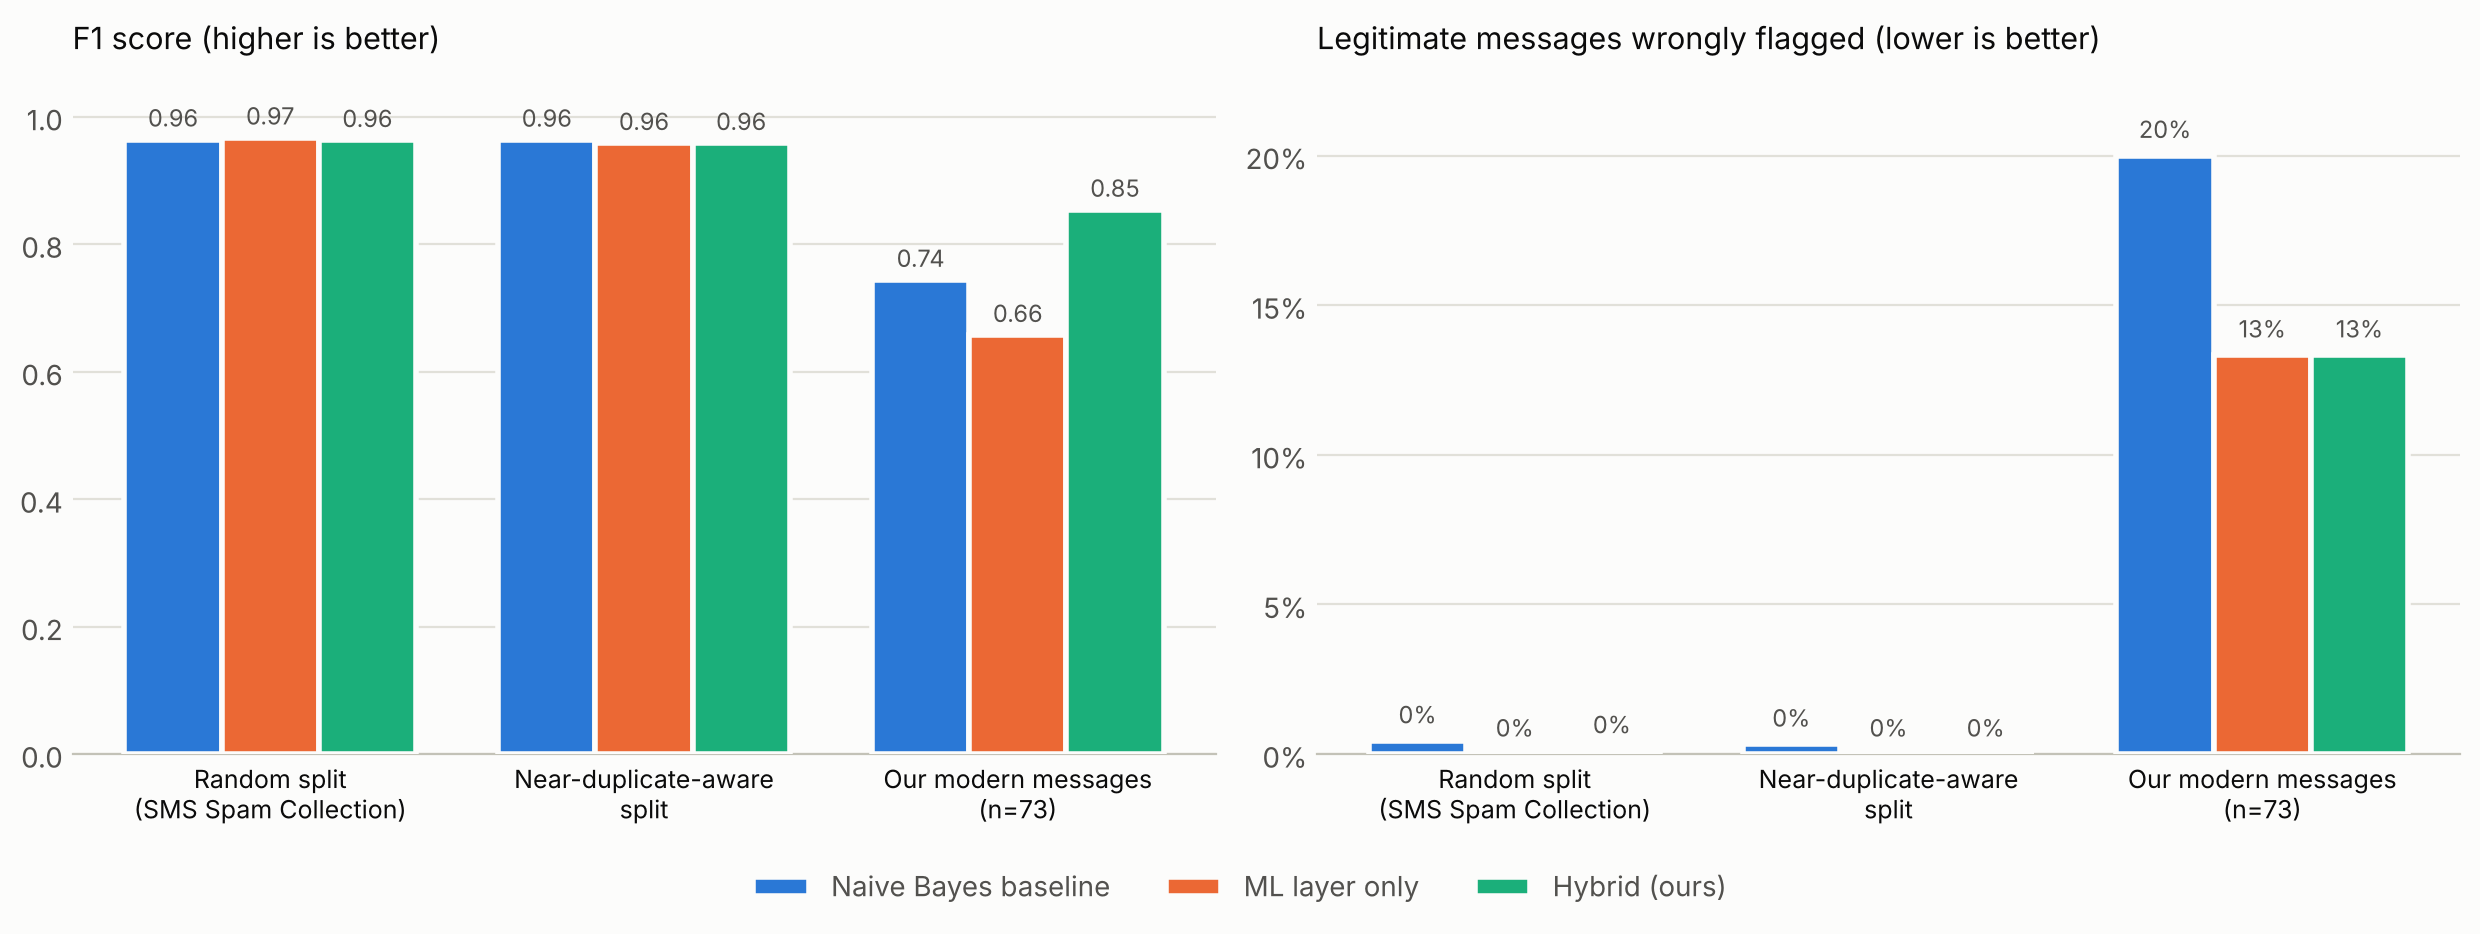

In [17]:
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e1e0d9"
SERIES = {"Naive Bayes baseline": "#2a78d6", "ML layer only": "#eb6834", "Hybrid (ours)": "#1baf7a"}
KEYMAP = {BASE: "Naive Bayes baseline", ML: "ML layer only", HYB: "Hybrid (ours)"}
SETTINGS = [("Random split\n(SMS Spam Collection)", RESULTS["exp1"]["systems"]),
            ("Near-duplicate-aware\nsplit", RESULTS["exp2"]["systems"]),
            ("Our modern messages\n(n=73)", RESULTS["exp3"]["systems"])]

tbl = pd.DataFrame([{"test": s.replace("\n", " "), "system": KEYMAP[k], "F1": v["f1"], "false-alarm rate": v["false_alarm_rate"]}
                    for s, d in SETTINGS for k, v in d.items() if k in KEYMAP])
print(tbl.pivot(index="test", columns="system", values="F1").round(3).to_string())
print()
print(tbl.pivot(index="test", columns="system", values="false-alarm rate").round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), facecolor=SURFACE)
names = list(SERIES)
width = 0.26
for ax, metric, title, pct in ((axes[0], "f1", "F1 score (higher is better)", False),
                               (axes[1], "false_alarm_rate", "Legitimate messages wrongly flagged (lower is better)", True)):
    ax.set_facecolor(SURFACE)
    for j, (label, color) in enumerate(SERIES.items()):
        key = [k for k, v in KEYMAP.items() if v == label][0]
        vals = [d[key][metric] for _, d in SETTINGS]
        xs = np.arange(len(SETTINGS)) + (j - 1) * width
        bars = ax.bar(xs, vals, width=width, color=color, edgecolor=SURFACE, linewidth=2, label=label, zorder=3)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v + (0.012 if not pct else 0.004), f"{v:.0%}" if pct else f"{v:.2f}",
                    ha="center", va="bottom", fontsize=8.5, color=INK2)
    ax.set_xticks(np.arange(len(SETTINGS)))
    ax.set_xticklabels([s for s, _ in SETTINGS], fontsize=9, color=INK)
    ax.set_title(title, fontsize=11, color=INK, loc="left")
    ax.yaxis.grid(True, color=GRID, linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")
    ax.tick_params(axis="y", colors=INK2, length=0)
    ax.tick_params(axis="x", length=0)
    if pct:
        ax.set_yticks([0, 0.05, 0.10, 0.15, 0.20])
        ax.set_ylim(0, 0.23)
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    else:
        ax.set_ylim(0, 1.08)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False, fontsize=10, labelcolor=INK2,
           bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.savefig("fig_summary.png", dpi=160, facecolor=SURFACE, bbox_inches="tight")
plt.show()

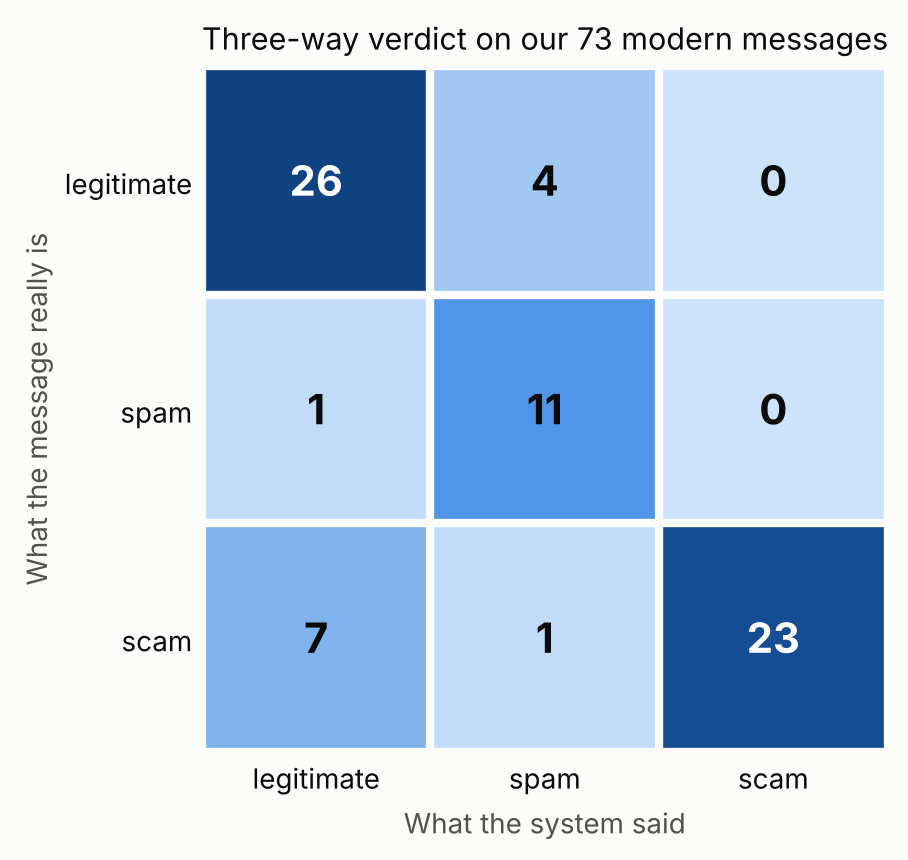

In [18]:
from matplotlib.colors import LinearSegmentedColormap

ramp = LinearSegmentedColormap.from_list("blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#104281"])
fig, ax = plt.subplots(figsize=(5.2, 4.4), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.imshow(cm.values, cmap=ramp, vmin=0, vmax=max(cm.values.max(), 1))
for i in range(3):
    for j in range(3):
        v = cm.values[i, j]
        ax.text(j, i, str(v), ha="center", va="center", fontsize=15, fontweight="bold",
                color="#ffffff" if v > cm.values.max() * 0.45 else INK)
ax.set_xticks(range(3)); ax.set_xticklabels(LABELS3, color=INK)
ax.set_yticks(range(3)); ax.set_yticklabels(LABELS3, color=INK)
ax.set_xlabel("What the system said", color=INK2)
ax.set_ylabel("What the message really is", color=INK2)
ax.set_title("Three-way verdict on our 73 modern messages", fontsize=11, color=INK, loc="left")
ax.set_xticks(np.arange(-.5, 3, 1), minor=True); ax.set_yticks(np.arange(-.5, 3, 1), minor=True)
ax.grid(which="minor", color=SURFACE, linewidth=3)
ax.tick_params(which="both", length=0)
for s in ax.spines.values():
    s.set_visible(False)
plt.tight_layout()
plt.savefig("fig_confusion_modern.png", dpi=160, facecolor=SURFACE, bbox_inches="tight")
plt.show()

## 9. What a person sees

Every verdict comes with its evidence. Two examples from our modern set, one scam and one legitimate message:

In [19]:
demo_msgs = [mt.text[mt.text.str.startswith("DHL: Your parcel")].iloc[0],
             mt.text[mt.text.str.startswith("UPS: Your package will be delivered")].iloc[0]]
for t in demo_msgs:
    print(f'"{t}"\n')
    print(final.classify(t).pretty())
    print("\n" + "-" * 70 + "\n")

"DHL: Your parcel could not be delivered. Select a new delivery date: dhl-parcel-reschedule.com/track"

🚨 SCAM   (risk 89/100, ML P(unwanted)=0.26, flagged by: rules)
  Link red flags:
    - Link impersonates 'dhl'  [dhl-parcel-reschedule.com/track]
  Social-engineering tactics:
    - Claims to be a company or authority  [Your parcel]
    - Fake delivery / parcel problem  [parcel could not]
  Advice: Do NOT tap links, call numbers or reply (even 'STOP'). If it claims to be a company, contact them through their official app or website instead. Report and delete.

----------------------------------------------------------------------

"UPS: Your package will be delivered today between 2 and 6 PM. Track it at https://www.ups.com/track"

✅ LEGITIMATE   (risk 26/100, ML P(unwanted)=0.07, flagged by: none)
  Social-engineering tactics:
    - Claims to be a company or authority  [Your package]
  Advice: No strong red flags. Still verify any unexpected request through a channel you trust.

---

In [20]:
RESULTS["dataset_note"] = "ML layer trained on de-duplicated SMS Spam Collection; modern set written after the model was frozen."
with open("results.json", "w") as f:
    json.dump(RESULTS, f, indent=2, default=float)
print("Saved results.json, fig_summary.png, fig_confusion_modern.png, modern_test_predictions.csv")

Saved results.json, fig_summary.png, fig_confusion_modern.png, modern_test_predictions.csv


## 10. Limitations and next steps

**Limitations**
- **Old, English-only training data.** The ML layer learned from mid-2000s UK texts. It has never seen a toll-payment scam, a QR-code scam or a message in Spanish.
- **The scam tier is rule-derived.** Our rules encode patterns we know; they were not learned from labeled scams, and our modern test set was written by us, so its scores are optimistic.
- **Real notices that look like scams.** Legitimate bank alerts and security notices use the same words as phishing ("unusual activity", "verify"). Telling them apart needs modern legitimate examples to learn from.
- **Leetspeak and other creative spelling** still slips past the text rules (Section 7).
- **We never visit links**, so a brand-new malicious site on a normal-looking domain is invisible to us.

**Next steps**
1. Collect real, consented modern messages (a public smishing dataset, or volunteers' forwarded spam and legitimate alerts) and retrain, so the scam tier is learned rather than hand-written.
2. Add a live link-reputation lookup (for example Google Safe Browsing) behind an explicit user opt-in.
3. Test with real users, such as parents and grandparents, to see whether the explanations change what they do.

## 11. Credits

- **Dataset:** Almeida, T. & Hidalgo, J. (2011). *SMS Spam Collection* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5CC84 (CC BY 4.0).
- **Libraries:** [scikit-learn](https://scikit-learn.org), [NumPy](https://numpy.org), [SciPy](https://scipy.org), [pandas](https://pandas.pydata.org), [Matplotlib](https://matplotlib.org), [joblib](https://joblib.readthedocs.io), [Python](https://www.python.org).
- **AI tool:** [Claude](https://claude.ai) (Anthropic) helped write and debug the code, design the evaluation, write the modern test messages and draft the write-up.
- **Test messages:** the 73 modern messages are invented; phone numbers use the reserved 555-01xx range and domains are made up.